Практическая работа №7: Исследовательский анализ данных и базовая визуализация

In [1]:
%pip install seaborn

In [2]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Настройка стиля графиков
sns.set_theme(style='whitegrid')

data_dir = 'data' if os.path.exists('data') else '.'

# Загружаем и объединяем все файлы заказов
order_files = sorted(glob.glob(os.path.join(data_dir, 'orders_2024_*.csv')))
df_orders = pd.concat([pd.read_csv(f) for f in order_files], ignore_index=True)

# Вычисляем выручку для каждой позиции (цена * количество)
df_orders['revenue'] = df_orders['price'] * df_orders['quantity']

print(f'Всего записей заказов: {len(df_orders)}')
print(df_orders[['price', 'quantity', 'revenue']].head().to_string())

Всего записей заказов: 15000
      price  quantity   revenue
0  14038.15         1  14038.15
1   9172.60         1   9172.60
2   9035.26         2  18070.52
3  15234.33         3  45702.99
4   4134.38         2   8268.76


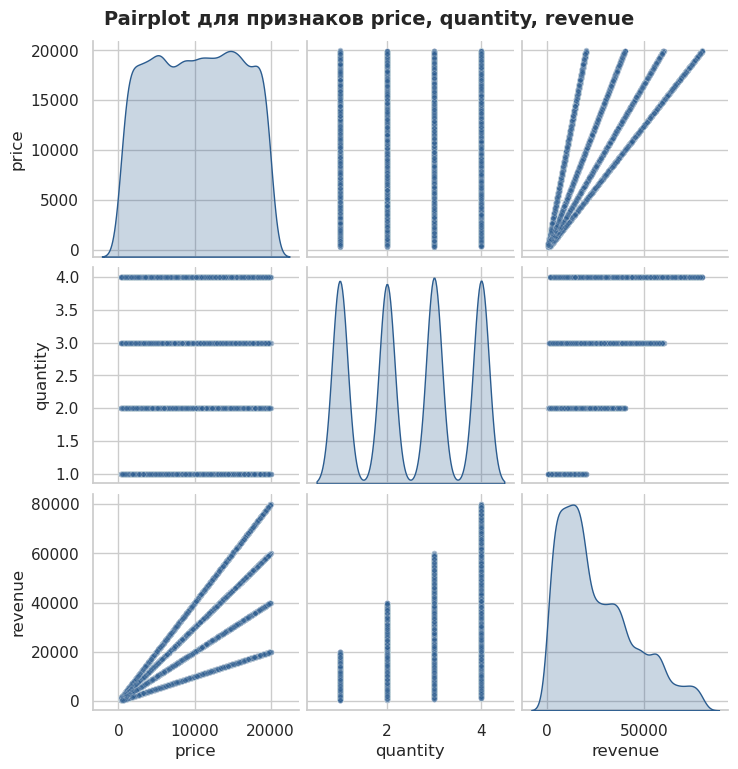

In [3]:
# Построение матрицы диаграмм рассеяния (Pairplot)
pairplot_fig = sns.pairplot(
    df_orders[['price', 'quantity', 'revenue']],
    diag_kind='kde',
    plot_kws={'alpha': 0.25, 's': 15, 'color': '#2b5c8f'},
    diag_kws={'color': '#2b5c8f', 'fill': True},
)

pairplot_fig.fig.suptitle(
    'Pairplot для признаков price, quantity, revenue',
    y=1.02,
    fontsize=14,
    fontweight='bold',
)
plt.show()

Матрица корреляций:
           price  quantity  revenue
price     1.0000    0.0116   0.7368
quantity  0.0116    1.0000   0.5999
revenue   0.7368    0.5999   1.0000


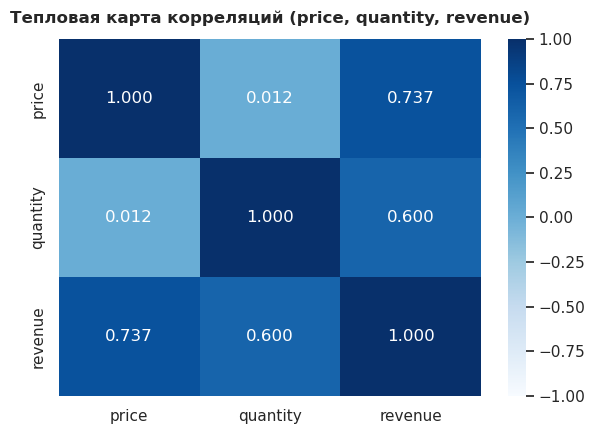

In [4]:
# Матрица парных корреляций Пирсона
numeric_features = ['price', 'quantity', 'revenue']
corr_matrix = df_orders[numeric_features].corr()

print('Матрица корреляций:')
print(corr_matrix.round(4).to_string())

# Визуализация матрицы корреляций в виде тепловой карты (Heatmap)
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=-1,
    vmax=1,
    cbar=True,
)
plt.title(
    'Тепловая карта корреляций (price, quantity, revenue)',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.show()

In [5]:
# Извлекаем уникальные пары признаков без диагонали
corr_unstacked = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).unstack()
corr_pairs = corr_unstacked.dropna()

# 3. Самая сильная положительная связь
strongest_pos = corr_pairs.idxmax()
strongest_val = corr_pairs.max()

# 4. Самая слабая связь (по модулю ближе всего к 0)
weakest = corr_pairs.abs().idxmin()
weakest_val = corr_pairs[weakest]

print(f"Самая сильная положительная связь: между '{strongest_pos[0]}' и '{strongest_pos[1]}'")
print(f'   Коэффициент корреляции r = {strongest_val:.4f}\n')

print(f"Самая слабая связь: между '{weakest[0]}' и '{weakest[1]}'")
print(f'   Коэффициент корреляции r = {weakest_val:.4f}')

Самая сильная положительная связь: между 'revenue' и 'price'
   Коэффициент корреляции r = 0.7368

Самая слабая связь: между 'quantity' и 'price'
   Коэффициент корреляции r = 0.0116


Вывод:
Независимость объема покупки от цены: Корреляция между price и quantity близка к нулю (r = 0.012). Это свидетельствует о том, что покупатели одинаково часто заказывают от 1 до 4 штук как дешевых, так и дорогих позиций (в данных отсутствует эффект снижения спроса в штуках при росте цены товара).
Драйвер выручки: Цена позиции (price) коррелирует с итоговой выручкой сильнее (r = 0.737), чем количество единиц в позиции (quantity, r = 0.600). Соответственно, средний чек в магазине сильнее масштабируется за счет продаж более дорогостоящих артикулов, чем за счет увеличения числа штук одного товара в корзине.